## Figure 1

- a) Forecast Anomaly: Hatching agreement < 80% ensemble members
- b) Method Diagram: Single region, single month (currently January), average histogram (across ensemble members or reanalysis years)
- c) Slope @ Avg Forecast

In [2]:
import sys
from pathlib import Path

PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "utils").is_dir()
)
sys.path.insert(0, str(PROJECT_ROOT))

import importlib
import os
from datetime import UTC, datetime

import cartopy.crs as ccrs
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr
from dotenv import find_dotenv, load_dotenv

from utils import analysis_utils, isku_utils, plotting_utils, stats_utils

importlib.reload(analysis_utils)
importlib.reload(isku_utils)
importlib.reload(plotting_utils)

/Users/kellymccusker/LOCAL/ClimateImpactLab/enso_mortality/enso_paper/ezuetell/mccusker_seasonal_2026/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<module 'utils.plotting_utils' from '/Users/kellymccusker/LOCAL/ClimateImpactLab/enso_mortality/enso_paper/ezuetell/mccusker_seasonal_2026/utils/plotting_utils.py'>

In [3]:
load_dotenv(
    find_dotenv(".env", raise_error_if_not_found=True), override=True
)

EFFECTS_URI = os.environ["POREALLAS_EFFECTS_URI"]
IMPACT_REGION_POLYGONS = os.environ["POREALLAS_REGIONS_POLYGONS_URI"]
SOCIOECONOMICS_URI = os.environ["POREALLAS_SOCIOECONOMICS_URI"]

# Climate Data
# TAS_FORECAST_URI = "../data/v2610/v20261006_parsed_forecast.zarr"
ERA5_URI = os.environ["POREALLAS_ERA5_URI"]
TAS_FORECAST_RAW = os.environ["POREALLAS_PARSED_FORECAST_URI"]#"../data/v2610/v20261006_parsed_forecast.zarr"
TAS_HINDCAST_RAW = os.environ["POREALLAS_PARSED_HINDCAST_URI"]


In [4]:
# Baseline period for Impact
effect = xr.open_datatree(EFFECTS_URI, consolidated=False)
BASELINE_PERIOD = analysis_utils.get_baseline_period(effect, years=30)
print("BASELINE_PERIOD", BASELINE_PERIOD)
# Define Forecast Months
FC_MONTHS = [10, 11, 12, 1, 2, 3]

config = analysis_utils.ImpactConfig(
    version=f"v{datetime.now(tz=UTC):%y%m%d}",
    baseline_period=BASELINE_PERIOD,
    polygons_path=os.environ["POREALLAS_REGIONS_POLYGONS_URI"],
    socioeconomics_path=os.environ["POREALLAS_SOCIOECONOMICS_URI"],
    rate=True,
    age_weight=True,
    months=FC_MONTHS,
    hotonly="hotonly",
    dims=["number", "sample"],
)

BASELINE_PERIOD slice('1996', '2025', None)


In [5]:
def bin_edges(tas_bin):
    # Standardize bin edges for discrete plotting
    tas_bin = np.asarray(tas_bin)
    return np.append(tas_bin, tas_bin[-1] + np.diff(tas_bin)[-1])


def _flat(da):
    # Flatten and check xarray
    v = np.asarray(da).ravel()
    return v[np.isfinite(v)]

In [6]:
## Climate Data Processing ##
def select_climate(forecast, reanalysis, region, month=None, pad=3):
    # Subset climate data
    fc = forecast.sel(region=region)
    era5 = reanalysis.sel(region=region)

    # Optionally select a single month
    if month is not None:
        era5 = era5.where(era5.month.isin([month]).compute(), drop=True)
        fc = fc.sel(time=fc.time.dt.month == month)

    vals = np.concatenate([_flat(fc), _flat(era5)])
    return {
        "forecast": fc,
        "era5": era5,
        "n_members": fc.sizes["number"],
        "n_years": np.unique(era5.time.dt.year).size,
        "xlim": (vals.min() - pad, vals.max() + pad),
    }


def plot_climate_hist(ax, clim, edges):
    # Plot climate histograms
    # Weighted for "days per month" across ERA5 years and forecast members
    for key, n, color, label in [
        ("era5", clim["n_years"], b_color, "ERA5"),
        ("forecast", clim["n_members"], f_color, "Forecast"),
    ]:
        v = _flat(clim[key])
        ax.hist(
            v,
            bins=edges,
            weights=np.full(v.size, 1 / n),
            alpha=0.5,
            color=color,
            label=label,
        )
    ax.set_xlim(*clim["xlim"])

In [7]:
## Response Curve ##
def select_betas(betas, mmt, region, age_cohort="age65plus"):
    # Subset response curve
    b = betas.sel(region=region, age_cohort=age_cohort).transpose("sample", "tas_bin")
    return {
        "samples": b.values,  # (sample, tas_bin)
        "tas_bin": b["tas_bin"].values,
        "mmt": mmt.sel(region=region, age_cohort=age_cohort).mean("sample").item(),
    }


def plot_response(ax, beta, ylim=(0, 10)):
    # Plot response curve and samples
    x, s = beta["tas_bin"], beta["samples"]
    # samples
    ax.step(x, s.T, where="pre", color=r_color, lw=0.5, alpha=0.15)
    # Average gamma sample
    ax.step(
        x,
        np.nanmean(s, axis=0),
        where="pre",
        color=r_color,
        lw=2,
        label="Response curve",
    )
    # MMT
    ax.axvline(beta["mmt"], color=r_color, lw=1, label="MMT")
    ax.set_ylim(*ylim)
    ax.spines["top"].set_visible(False)

In [8]:
## CDF ##
def compute_cdf(clim, beta, q=(5, 95)):
    # CDF and Uncertainty Range
    edges = bin_edges(beta["tas_bin"])
    out = {"x": beta["tas_bin"]}
    for key, n in [("era5", clim["n_years"]), ("forecast", clim["n_members"])]:
        counts, _ = np.histogram(_flat(clim[key]), bins=edges)
        # Cumulative mortality rate = response curve * histogram / num. samples
        cdf = np.cumsum(beta["samples"] * counts / n, axis=1)  # (sample, tas_bin)
        out[key] = {
            "mean": np.nanmean(cdf, axis=0),
            "lo": np.nanpercentile(cdf, q[0], axis=0),
            "hi": np.nanpercentile(cdf, q[1], axis=0),
        }
    # Log for ylim
    out["max"] = max(out["era5"]["hi"].max(), out["forecast"]["hi"].max())
    return out


def plot_cdf(ax, cdf):
    # Add CDF for forecast and era5 to plot
    for key, color, label in [
        ("forecast", f_color, "Forecast"),
        ("era5", b_color, "ERA5"),
    ]:
        c = cdf[key]
        ax.fill_between(
            cdf["x"], c["lo"], c["hi"], step="pre", color=color, alpha=0.25, lw=0
        )
        ax.step(cdf["x"], c["mean"], where="pre", color=color, label=label)
    ax.set_ylim(0, cdf["max"] * 1.1)

In [9]:
def plot_region_panel(
    fig, spec, region, title=None, show_left_labels=True, show_right_labels=True
):
    # Subset and compute hist and cdf
    clim = select_climate(
        forecast_ir["tas"], era5_ir["tas"], region, month=1 # accessing globals here
    )  # All ensemble members, era5 years
    beta = select_betas(betas, betas_mmt["mmt"], region) # accessing globals here
    cdf = compute_cdf(clim, beta)
    # Setup gridspec
    inner = spec.subgridspec(2, 1, height_ratios=[3, 1], hspace=0.08)
    ax_hist = fig.add_subplot(inner[0])
    ax_cdf = fig.add_subplot(inner[1], sharex=ax_hist)
    ax_resp = ax_hist.twinx()
    ax_hist.tick_params(labelbottom=False)
    # Plot hist and curves
    plot_climate_hist(ax_hist, clim, bin_edges(beta["tas_bin"]))
    plot_response(ax_resp, beta)
    plot_cdf(ax_cdf, cdf)
    # Labels
    ax_cdf.set_xlabel("Tas [°C]")
    if show_left_labels:
        ax_hist.set_ylabel("Days per Month")
        ax_cdf.set_ylabel("Cum. effect\n[Deaths/100k]")
    if show_right_labels:
        ax_resp.set_ylabel("Daily Response 65+\n[deaths/100k]")
    ax_hist.set_title(title or str(region))

    return ax_hist, ax_resp, ax_cdf

In [10]:
def merge_regions(ds, socioec_ds, forecast_ds):
    # Merge betas and socioeconomics
    if isinstance(ds, xr.DataTree):
        ds = ds.to_dataset()
    merged = xr.merge(
        [ds, socioec_ds[["pop"]], forecast_ds[["forecast_mean", "forecast_std"]]],
        join="inner",
    )

    return merged


def filter_regions(merged, min_population, min_dist_from_mmt, max_dist_from_mmt):
    """
     select regions where population >= min_population and
    |forecast_mean - mmt| <= max_dist_from_mmt.

    mmt in ds has dims (sample, age_cohort, region) — collapsed across sample/age_cohort
    (mean) to get a single per-region MMT for the distance filter.
    """
    mmt_per_region = merged["mmt"].mean(dim=["sample", "age_cohort"])
    dist_from_mmt = np.abs(merged["forecast_mean"] - mmt_per_region)

    region_mask = (
        (merged["pop"] >= min_population)
        & (dist_from_mmt <= max_dist_from_mmt)
        & (dist_from_mmt >= min_dist_from_mmt)
    )
    selected_regions = merged["region"].values[region_mask.values]

    return merged.sel(region=selected_regions)


def compute_slope_at_forecast(merged):
    """
    Compute d(beta)/d(tas) evaluated at each region's forecast_mean,
    for every sample and age_cohort.
    """
    tas_bin = merged["tas_bin"].values

    def _slope_at_point(beta_curve, x0):
        # beta_curve: 1D array over tas_bin; x0: scalar forecast_mean for this region
        dbeta_dtas = np.gradient(beta_curve, tas_bin)
        return np.interp(x0, tas_bin, dbeta_dtas)

    slope = xr.apply_ufunc(
        _slope_at_point,
        merged["beta"],
        merged["forecast_mean"],
        input_core_dims=[["tas_bin"], []],
        output_core_dims=[[]],
        vectorize=True,
        dask="parallelized",
        output_dtypes=[merged["beta"].dtype],
    )

    return slope.rename("beta_slope_at_forecast")

In [11]:
### Load RAW Climate Data ###
forecast = xr.open_zarr(
    TAS_FORECAST_RAW
)  # Daily ensemble member temp
hindcast = xr.open_zarr(
    TAS_HINDCAST_RAW
)  # Daily ensemble mean temp

# Monthly avg temp
forecast_month = forecast.groupby("time.month").mean().sel(month=config.months)
hindcast_month = hindcast.groupby("time.month").mean()
# Monthly anomaly relative to 1996-2025 climatological baseline
fc_anomaly = forecast_month["tas"] - hindcast_month["tas"]

# Impact region Level
# Gridded to Impact Region
forecast_ir = isku_utils.grid_to_ir(forecast - 273.15, savefile=None)  # Convert to C

forecast_ds = forecast_ir.groupby("time.month").mean()
forecast_ds = forecast_ds.assign(
    forecast_mean=forecast_ds["tas"].mean(dim=["number"]),
    forecast_std=forecast_ds["tas"].std(dim=["number"]),
)

# Clip Grid to Land Only
fc_land = analysis_utils.land_only(
    (fc_anomaly), lat_name="lat", lon_name="lon", clip_antarctica=False
)  # Leave Antarctica in computation

### Load Forecast Data ###
anom = fc_land.mean(dim=["month"])  # 6-month avg anomaly TODO weight by number of days in month
ens_mean = anom.mean("number")  # ensemble mean

print(anom)
print(forecast_ds) # this has 8 months in it!! @@@

<xarray.DataArray 'tas' (number: 51, lat: 180, lon: 360)> Size: 13MB
dask.array<mean_agg-aggregate, shape=(51, 180, 360), dtype=float32, chunksize=(51, 30, 2), chunktype=numpy.ndarray>
Coordinates:
  * number   (number) int64 408B 0 1 2 3 4 5 6 7 8 ... 43 44 45 46 47 48 49 50
  * lat      (lat) float64 1kB 89.5 88.5 87.5 86.5 ... -86.5 -87.5 -88.5 -89.5
  * lon      (lon) float64 3kB -179.5 -178.5 -177.5 -176.5 ... 177.5 178.5 179.5
Attributes: (12/31)
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      64800
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    GRIB_gridType:                            regular_ll
    ...                                       ...
    units:                                    K
    standard_name:                            unknown
    GRIB_surface:                             0.0
    poreallas_created_at:  

In [12]:

# BASELINE
era5 = xr.open_zarr(ERA5_URI, storage_options={"token": "anon"},).sel(time=slice("1996-01-01", "2025-12-31")) - 273.15
era5_ir = isku_utils.grid_to_ir(era5, savefile=None)
era5_ir = era5_ir.assign_coords(month=era5_ir["time"].dt.month)

print(era5_ir)

<xarray.Dataset> Size: 1GB
Dimensions:  (region: 24378, time: 10950)
Coordinates:
  * region   (region) object 195kB 'ABW' ... 'ZWE.9.R19a261b63a503c9c'
  * time     (time) object 88kB 1996-01-01 00:00:00 ... 2025-12-31 00:00:00
    month    (time) int64 88kB 1 1 1 1 1 1 1 1 1 ... 12 12 12 12 12 12 12 12 12
Data variables:
    tas      (region, time) float32 1GB dask.array<chunksize=(2993, 10950), meta=np.ndarray>
Attributes:
    poreallas_created_at:   2026-09-03T22:05:06.958345+00:00
    poreallas_uid:          b6cf0bfa-2860-4f18-8818-51a1ec95d007
    poreallas_description:  QDM bias-adjusted ERA5 climate fields


In [13]:

# BETAS
betas_mmt = effect["/fixed_beta"]
print(betas_mmt)

# Load Response Curve
betas = betas_mmt["beta_hotonly"] if config.hotonly == "hotonly" else betas_mmt["beta"] # used only inside a plot func
# betas_mean = betas.mean(dim="sample") # don't call this betas_sample b/c it's actuall betas_mean. Also never used?
print(betas)


<xarray.DataTree 'fixed_beta'>
Group: /fixed_beta
    Dimensions:        (sample: 100, age_cohort: 3, region: 24378, tas_bin: 170,
                        degree: 4, covarname: 3)
    Coordinates:
      * sample         (sample) int64 800B 0 1 2 3 4 5 6 7 ... 93 94 95 96 97 98 99
      * age_cohort     (age_cohort) StringDType() 48B 'age0to4' ... 'age65plus'
      * region         (region) StringDType() 390kB 'ABW' ... 'ZWE.9.R19a261b63a5...
      * tas_bin        (tas_bin) float64 1kB -104.5 -103.5 -102.5 ... 62.5 63.5 64.5
      * degree         (degree) int64 32B 1 2 3 4
      * covarname      (covarname) StringDType() 48B '1' 'climtas' 'loggdppc'
    Data variables:
        beta           (sample, age_cohort, region, tas_bin) float32 5GB ...
        climtas        (region) float32 98kB ...
        loggdppc       (region) float32 98kB ...
        beta_hotonly   (sample, age_cohort, region, tas_bin) float32 5GB ...
        mmt            (sample, age_cohort, region) float32 29MB ...


In [14]:

# Set MMT as median bin when response curve is 'flat' -> Clipped
# min_val = betas_mmt["beta"].min(dim="tas_bin")
# is_min = betas_mmt["beta"] == betas_mmt["beta"].min(dim="tas_bin")

# # Median MMT --> I'm not seeing this used anywhere else here
# central_tas_bin = betas_mmt["tas_bin"].where(
#     betas_mmt["beta"] == betas_mmt["beta"].min(dim="tas_bin")
#     ).median(dim="tas_bin", skipna=True)


In [16]:

# Load Betas
#ds1 = effect["/fixed_beta"]
betas_for_slopes = merge_regions(betas_mmt, config.socioeconomics, forecast_ds)[["beta","forecast_mean"]]#.compute()
# Filter regions w/ 0 pop
# betas_for_slopes = ds1.where(betas_for_slopes["pop"] > 1, drop=True)
print(betas_for_slopes.nbytes/1024**3) # oh yeah almost 14GB
print(betas_for_slopes)




4.632663376629353
<xarray.Dataset> Size: 5GB
Dimensions:        (sample: 100, age_cohort: 3, region: 24378, tas_bin: 170,
                    month: 8)
Coordinates:
  * sample         (sample) int64 800B 0 1 2 3 4 5 6 7 ... 93 94 95 96 97 98 99
  * age_cohort     (age_cohort) StringDType() 48B 'age0to4' ... 'age65plus'
  * region         (region) StringDType() 390kB 'ABW' ... 'ZWE.9.R19a261b63a5...
  * tas_bin        (tas_bin) float64 1kB -104.5 -103.5 -102.5 ... 62.5 63.5 64.5
  * month          (month) int64 64B 1 2 3 4 5 10 11 12
    year           int64 8B 2026
Data variables:
    beta           (sample, age_cohort, region, tas_bin) float32 5GB ...
    forecast_mean  (month, region) float32 780kB dask.array<chunksize=(8, 66), meta=np.ndarray>
Attributes:
    poreallas_created_at:            2026-10-09T06:05:51.263762+00:00
    poreallas_uid:                   85afc240-ce90-4b7d-842a-2dab429566d4
    poreallas_description:           Fixed betas or temperature-mortality rat...
    po

In [17]:
# wittle betas_for_slopes down -> this crashes the kernel
betas_for_slopes = betas_for_slopes.sel(age_cohort="age65plus").sel(month=config.months).mean(dim="month").compute()


: 

In [ ]:

# Slope Map 
slope = compute_slope_at_forecast(betas_for_slopes)
_polygons_slope = analysis_utils.xarray_to_gpd(
    slope.mean(dim="sample"), config.polygons
)


## Build Figure

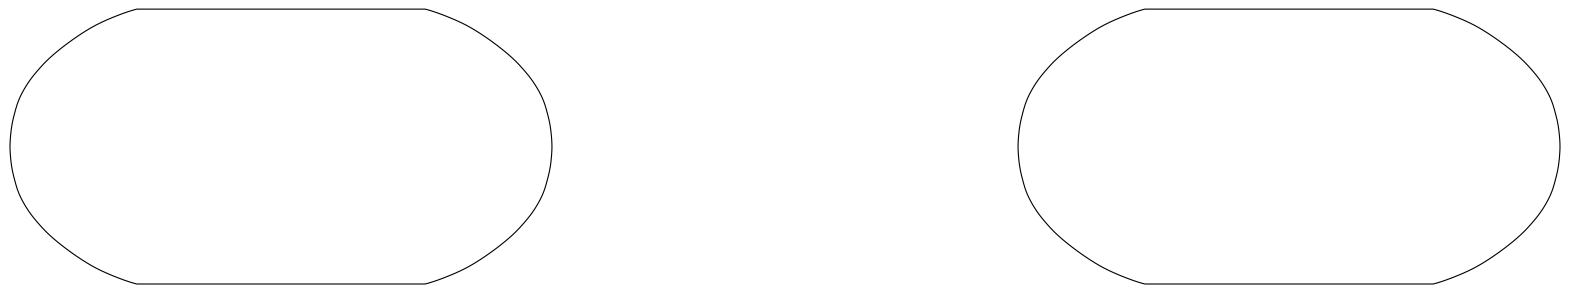

In [16]:
### Set Colors ###
b_color = "#999999"
f_color = "#ffbb6f"
r_color = "#5e4c5f"

fig = plt.figure(figsize=(20, 5.5))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 0.6, 1], wspace=0.15)

ax_map1 = fig.add_subplot(gs[0], projection=ccrs.Robinson())  # Forecast
ax_map3 = fig.add_subplot(gs[2], projection=ccrs.Robinson())  # Slope

In [17]:
### Plot Forecast Mean ###
step = 0.5
vmax = np.ceil(float(abs(ens_mean).quantile(0.98)) / step) * step
levels = np.arange(-vmax, vmax + step, step)
# Plot ensemble mean
mesh = ens_mean.plot.pcolormesh(
    ax=ax_map1,
    transform=ccrs.PlateCarree(),
    cmap="RdBu_r",
    levels=levels,
    extend="both",
    add_colorbar=False,
)

ax_map1.coastlines(linewidth=0.6, color="k")

ax_map1.set_extent([-180, 180, -60, 90], crs=ccrs.PlateCarree())
ax_map1.spines["geo"].set_visible(False)

fig.colorbar(
    mesh,
    ax=ax_map1,
    orientation="horizontal",
    shrink=0.6,
    pad=0.05,
    label="Temperature anomaly (°C)",
)
# Add Hatching: T-Test across ensemble members, alpha = 0.05
mask = stats_utils.compute_agreement_mask(anom, threshold=0.8, member_dim="number")
plotting_utils.add_polygons(ax_map1, mask, transform=ccrs.PlateCarree())

In [ ]:

cmap = plt.get_cmap("coolwarm")
levels = np.linspace(-1, 1, 13 + 1)
norm = mcolors.BoundaryNorm(levels, cmap.N, extend="both")

## Mask Out Caspian Sea ##
gdf_rob = _polygons_slope.to_crs(ccrs.Robinson().proj4_init)

gdf_rob.plot(
    ax=ax_map3,
    column="beta_slope_at_forecast",
    cmap=cmap,
    norm=norm,
    linewidth=0,
    aspect=None,
    missing_kwds={"color": "lightgray"},
)
ax_map3.coastlines(linewidth=0.6, color="k")
ax_map3.set_extent([-180, 180, -60, 90], crs=ccrs.PlateCarree())
ax_map3.spines["geo"].set_visible(False)
fig.colorbar(
    plt.cm.ScalarMappable(norm=norm, cmap=cmap),
    ax=ax_map3,
    orientation="horizontal",
    shrink=0.7,
    aspect=30,
    pad=0.03,
    label="Slope @ Avg. Forecast [Rate/C]",
)

In [55]:
# Plot Region Panel
region = "BWA.3"
ax_hist, ax_resp, _ = plot_region_panel(
    fig,
    gs[1],
    region,
    title="Kgalagadi, Botswana",
    show_left_labels=True,
    show_right_labels=True,
)

h1, l1 = ax_hist.get_legend_handles_labels()
h2, l2 = ax_resp.get_legend_handles_labels()
ax_resp.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8, frameon=False)

# ---- Panel labels ----
for label, a in zip("ac", [ax_map1, ax_map3]):
    a.text(
        0.0,
        1.03,
        f"({label})",
        transform=a.transAxes,
        fontsize=12,
        fontweight="bold",
        va="bottom",
        ha="left",
    )
ax_hist.text(
    -0.12,
    1.03,
    "(b)",
    transform=ax_hist.transAxes,
    fontsize=12,
    fontweight="bold",
    va="bottom",
    ha="left",
)

Text(-0.12, 1.03, '(b)')

In [ ]:
fig.savefig(f"{config.version}_method_diagram_map.png", dpi=600, bbox_inches="tight")

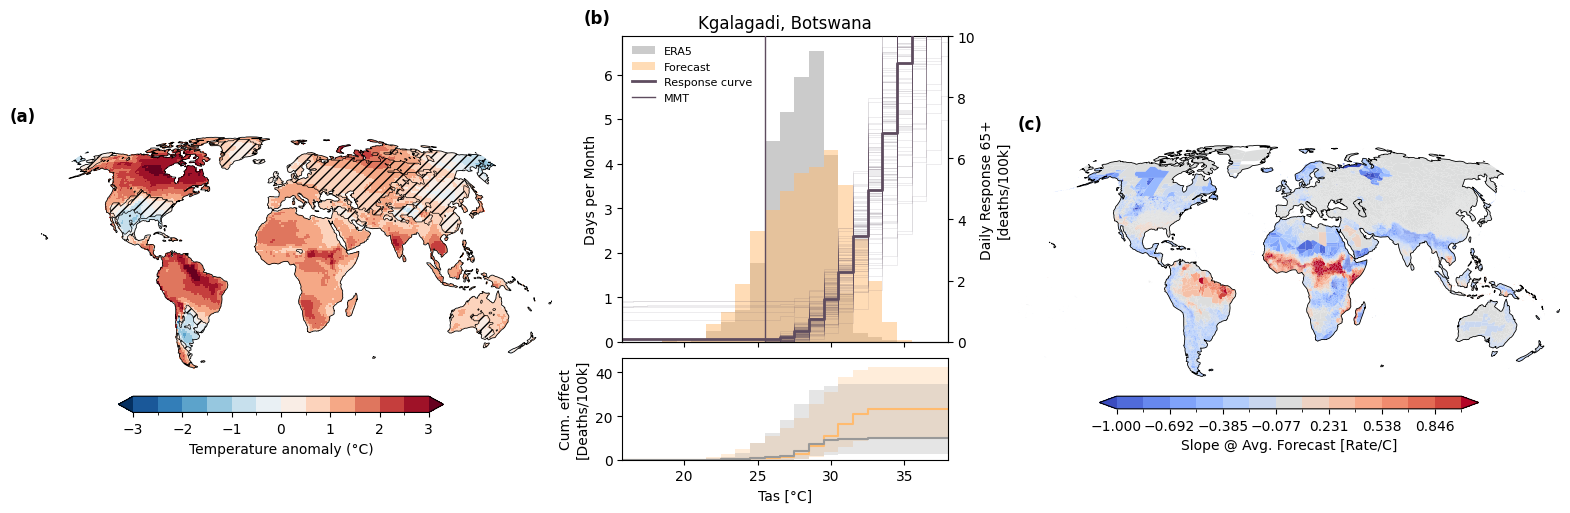

In [56]:
fig